# Análisis datos Manzano
El siguiente documento busca responder las siguientes preguntas analizando
* ¿Cuándo actúa la lluvia de invierno y cuándo el deshielo de verano?
* ¿Y qué papel juega la altura a la que deja de nevar y empieza a llover?

In [6]:
#Importamos las librerías necesarias para el análisis
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd

In [7]:
#Cargamos la base de datos
df_manzano = pd.read_csv("nivel1_manzano.csv")

In [ ]:
#Información de la base de datos
df_manzano.info()

<class 'pandas.DataFrame'>
RangeIndex: 9709 entries, 0 to 9708
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   fecha                  9709 non-null   str    
 1   anio_hidro             9709 non-null   int64  
 2   mes                    9709 non-null   int64  
 3   q_m3s                  9653 non-null   float64
 4   ssc_mgL                5258 non-null   float64
 5   ssc_hora_h             5140 non-null   float64
 6   p_mm                   9709 non-null   float64
 7   p_acum3d_mm            9709 non-null   float64
 8   t_media_C              9678 non-null   float64
 9   iso0_m                 9709 non-null   float64
 10  iso0_fuente            9709 non-null   str    
 11  frac_bajo_iso0         9709 non-null   float64
 12  p_liq_mm               9709 non-null   float64
 13  p_liq_48h_mm           9709 non-null   float64
 14  evento_documentado     9709 non-null   int64  
 15  evento_causa   

Preparación de la base de datos para construir gráficos:

In [10]:
mensual = df_manzano.groupby('mes')[['q_m3s', 'p_mm', 't_media_C' ]].mean().reset_index()
MESES = ["ene", "feb", "mar", "abr", "may", "jun",
         "jul", "ago", "sep", "oct", "nov", "dic"]

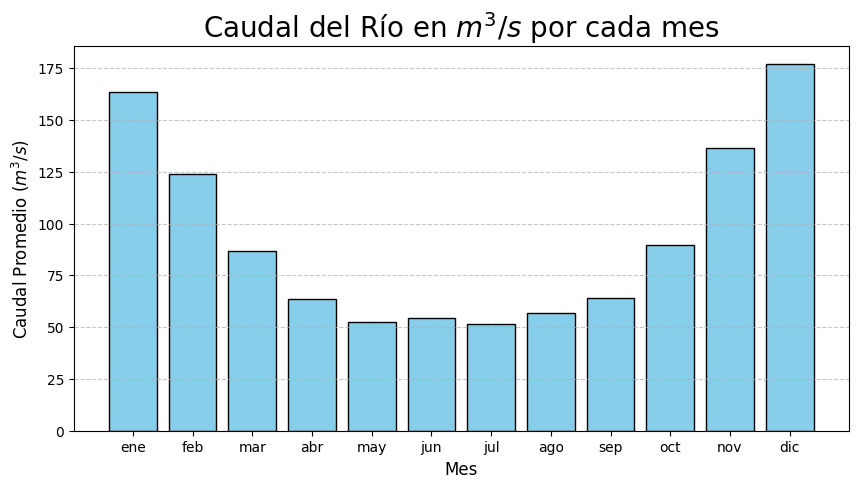

In [11]:
#Grafico de caudal de rio maipo
plt.figure(figsize=(10, 5))
plt.bar(mensual['mes'], mensual['q_m3s'], color='skyblue', edgecolor='black')
plt.title("Caudal del Río en $m^3/s$ por cada mes", fontsize=20)
plt.xlabel("Mes", fontsize=12)
plt.ylabel("Caudal Promedio ($m^3/s$)", fontsize=12)
plt.xticks(range(1, 13), MESES)
plt.grid(axis='y', linestyle='--', alpha=0.7)

**Gráfico de las precipitaciones en el rio:**

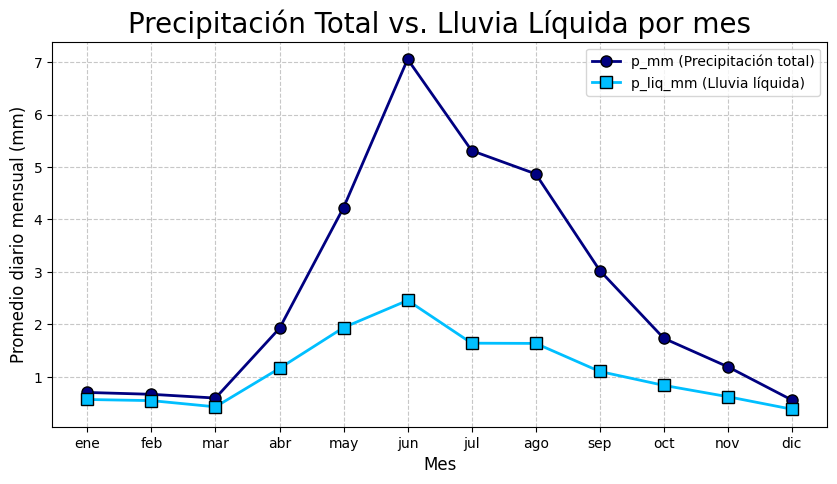

In [12]:
#Preparación de la base de datos para el análisis de precipitaciones
lluvias = df_manzano.groupby("mes")[["p_mm", "p_liq_mm", "p_liq_48h_mm"]].mean().reset_index()

#Grafico
plt.figure(figsize=(10, 5))
plt.plot(lluvias['mes'], lluvias["p_mm"], color='navy', marker='o', 
         linewidth=2, markeredgecolor='black', markersize=8, label="p_mm (Precipitación total)")

#Línea de lluvia líquida (p_liq_mm)
plt.plot(lluvias['mes'], lluvias["p_liq_mm"], color='deepskyblue', marker='s', 
         linewidth=2, markeredgecolor='black', markersize=8, label="p_liq_mm (Lluvia líquida)")

plt.title("Precipitación Total vs. Lluvia Líquida por mes", fontsize=20)
plt.xlabel("Mes", fontsize=12)
plt.ylabel("Promedio diario mensual (mm)", fontsize=12)
plt.xticks(range(1, 13), MESES)

# Cuadrícula y leyenda
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

plt.show()

**Estudio de la temperatura del río:**

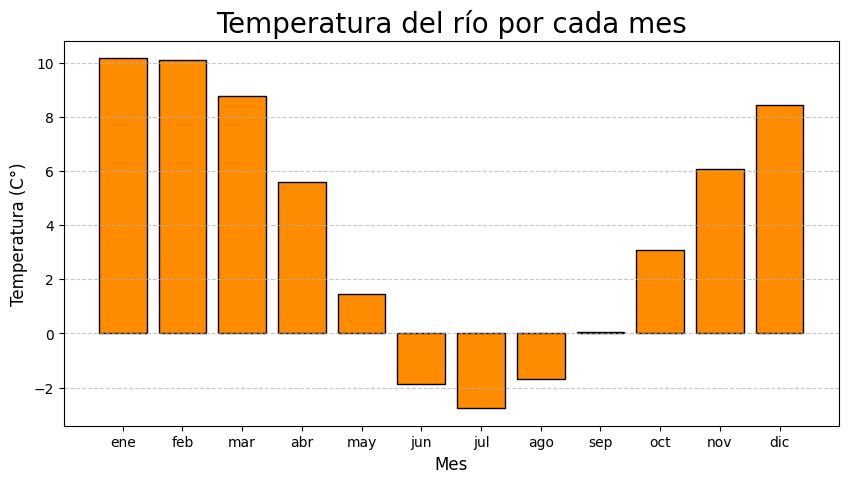

In [151]:
#Climatologia
cli = df_manzano.groupby("mes")[["q_m3s", "ssc_mgL", "p_mm", "t_media_C"]].median().reset_index()
plt.figure(figsize=(10, 5))
plt.bar(mensual['mes'], mensual['t_media_C'], color='darkorange', edgecolor='black')
plt.title("Temperatura del río por cada mes", fontsize=20)
plt.xlabel("Mes", fontsize=12)
plt.ylabel("Temperatura (C°)", fontsize=12)
plt.xticks(range(1, 13), MESES)
plt.grid(axis='y', linestyle='--', alpha=0.7)

**Relación entre caudal y temperatura:**

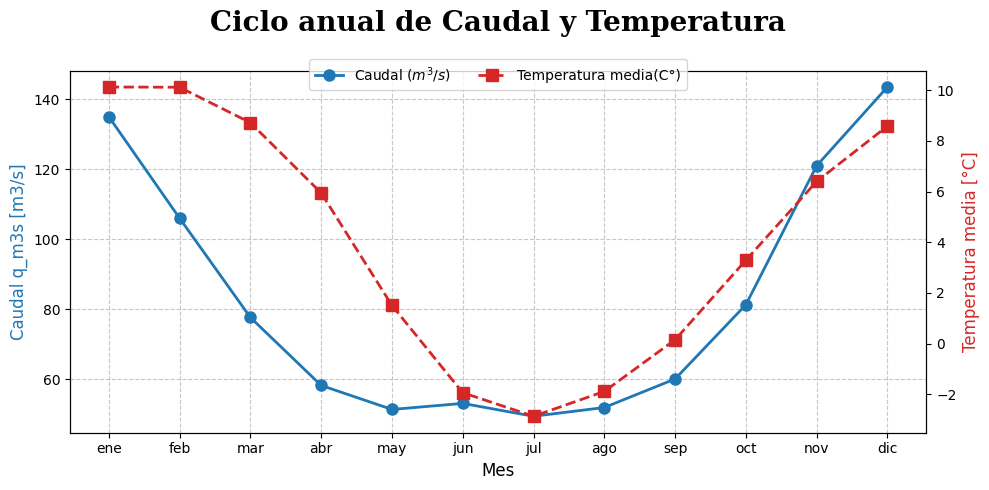

In [ ]:
plt.figure(figsize=(10, 5))

#Eje principal (Caudal)
line1 = plt.plot(cli["mes"], cli["q_m3s"], "o-", color="tab:blue", linewidth=2, markersize=8, label="Caudal ($m^3/s$)")
plt.ylabel("Caudal q_m3s [m3/s]", color="tab:blue", fontsize=12)
plt.xlabel("Mes", fontsize=12)
plt.xticks(range(1, 13), MESES)
plt.grid(True, linestyle='--', alpha=0.7)

# Segundo eje (Temperatura) - plt.twinx() crea el segundo eje a la derecha
ax2 = plt.twinx()
line2 = ax2.plot(cli["mes"], cli["t_media_C"], "s--", color="tab:red", linewidth=2, markersize=8, label="Temperatura media(C°)")
ax2.set_ylabel("Temperatura media [°C]", color="tab:red", fontsize=12)

# Título
# Se añade un salto de línea \n al final para dar espacio a la leyenda
plt.title("Ciclo anual de Caudal y Temperatura\n", fontsize=20, fontweight="bold", family='serif')

# Extraer etiquetas para combinar las leyendas de ambos ejes y colocarla arriba al centro
lines = line1 + line2
labels = [l.get_label() for l in lines]
plt.legend(lines, labels, loc="upper center", bbox_to_anchor=(0.5, 1.05), ncol=2)

plt.tight_layout()
plt.show()

**Explicación del ciclo anual:**
* **Deshielo de Verano:** Los caudales alcanzan su máximo histórico anual entre diciembre y enero. En esta época casi no hay lluvias, pero las temperaturas son altas. El caudal proviene exclusivamente de la nieve que se está derritiendo.
* **Lluvia de Invierno:** El caudal base es bajo debido a las bajas temperaturas, lo que evita que la nieve se derrita. Sin embargo, es en estos meses invernales cuando ocurren los grandes picos por eventos de lluvia intensa.

## 2. El papel de la Isoterma Cero
La isoterma cero es la altitud a la que la temperatura marca 0°C.
Si la precipitación ocurre por encima de esta marca, cae como nieve y se guarda para el deshielo en verano. Si ocurre por debajo de la isoterma, la precipitación cae como lluvia liquida.

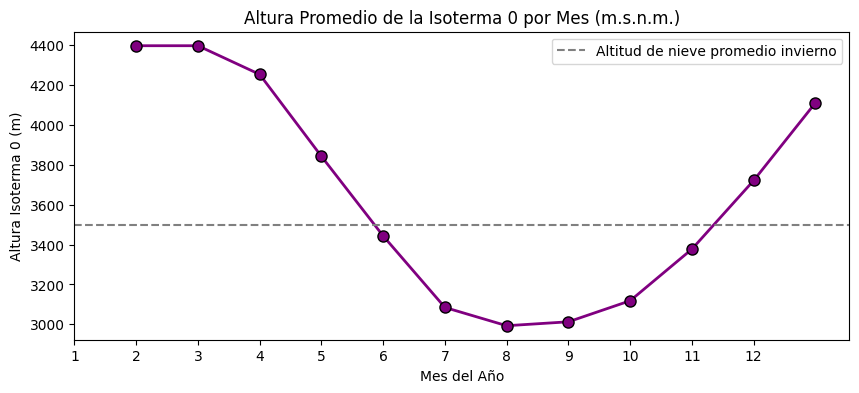

In [ ]:
#Isoterma 0 mensual
iso0_mensual = df_manzano.groupby('mes')['iso0_m'].mean().reset_index()

plt.figure(figsize=(10, 4))
plt.plot(iso0_mensual['mes'], iso0_mensual["iso0_m"], color='purple', marker='o', 
         linewidth=2, markeredgecolor='black', markersize=8)
plt.title('Altura Promedio de la Isoterma 0 por Mes (m.s.n.m.)')
plt.xlabel('Mes del Año')
plt.ylabel('Altura Isoterma 0 (m)')
plt.xticks(range(0, 12), range(1, 13))
plt.legend()
plt.show()